# Model comparison

In [1]:
import os
import random
from math import comb

import joblib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split

from kryptonet import load_kryptonet

SEED = 42
TARGET = 0.90
NS = (20, 30, 40)
FRACS = (0.25, 0.5, 1.0)
WEIGHT_ROOT = "./weights"


def set_seed(seed=42):
    """Set a seed for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

## Data

In [2]:
def load(name):
    """Load (X, y) arrays for a dataset."""
    return np.load(f"Datasets/{name}-X.npy"), np.load(f"Datasets/{name}-y.npy")


def split(X, y):
    """60% train, 20% validation, 20% test."""
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=SEED)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)
    return X_train, y_train, X_val, y_val, X_test, y_test


SPLITS = {}
for n in NS:
    X_train, y_train, X_val, y_val, X_test, y_test = split(*load(f"kryptonite-{n}"))
    SPLITS[n] = {"val": (X_val, y_val), "test": (X_test, y_test)}
    print(f"n={n}: {len(y_train)} train / {len(y_val)} val / {len(y_test)} test")

n=20: 7200 train / 2400 val / 2400 test
n=30: 12000 train / 4000 val / 4000 test
n=40: 19200 train / 6400 val / 6400 test


# Model code

In [3]:
def binarise(X):
    """Map each noisy +-1 feature to its sign."""
    return np.where(X > 0, 1.0, -1.0)


def mask_features(X, cols):
    """Zero out every feature not in `cols`, so KryptoNet still receives 40 inputs."""
    M = np.zeros_like(X)
    M[:, cols] = X[:, cols]
    return M


# --- baseline.ipynb: polynomial-kernel logistic regression in the dual ---
def agreements(X1, X2, n):
    """Number of agreeing bits between every pair of rows, after rounding the inputs to bits."""
    B1, B2 = np.sign(X1).astype(np.float32), np.sign(X2).astype(np.float32)
    return np.rint((n + B1 @ B2.T) / 2).astype(np.uint8)


def polyfeatures_kernel_table(n, degree):
    """phi(x).phi(x') for PolynomialFeatures(degree) on +-1 bits, indexed by the number m of agreeing bits."""
    table = np.zeros(n + 1)
    for s in range(degree + 1):
        weight = comb(n + (degree - s) // 2, n)
        e_s = [sum(comb(m, a) * comb(n - m, s - a) * (-1) ** (s - a) for a in range(s + 1)) for m in range(n + 1)]
        table += weight * np.array(e_s, dtype=float)
    return table / table[n]


def poly_kernel(X1, X2, degree, block=256):
    """phi(x).phi(x') for PolynomialFeatures(degree) on raw (not binarised) inputs, divided by the number of features.

    With z_i = x_i * x'_i this is sum_{k <= degree} h_k(z), where h_k is the complete homogeneous symmetric polynomial.
    h_k follows from the power sums p_j(z) = (X1**j) @ (X2**j).T by Newton's identities. On +-1 inputs it equals
    polyfeatures_kernel_table(n, degree)[agreements(X1, X2, n)].
    """
    n = X1.shape[1]
    P1 = [np.asarray(X1, np.float64) ** j for j in range(1, degree + 1)]
    P2 = [np.asarray(X2, np.float64).T ** j for j in range(1, degree + 1)]
    K = np.empty((len(X1), len(X2)), np.float32)
    for s in range(0, len(X1), block):
        p = [A[s:s + block] @ B for A, B in zip(P1, P2)]
        h = [np.ones_like(p[0])]
        for k in range(1, degree + 1):
            h.append(sum(p[j - 1] * h[k - j] for j in range(1, k + 1)) / k)
        K[s:s + block] = sum(h) / comb(n + degree, degree)
    return K


def kernel_predict(S_query, S_support, a, degree):
    """Labels from the dual weights `a` of `kernel_logreg`, using only the selected columns."""
    k = S_support.shape[1]
    table = polyfeatures_kernel_table(k, degree).astype(np.float32)
    return (table[agreements(S_query, S_support, k)] @ a > 0).astype(int)


# --- mlp.ipynb / mlp_no_fs.ipynb ---
class MLP(nn.Module):
    """Plain ReLU MLP that outputs one logit per row."""

    def __init__(self, d_in, hidden):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        self.net = nn.Sequential(*layers, nn.Linear(d, 1))

    def forward(self, x):
        return self.net(x).squeeze(1)


class ResBlock(nn.Module):
    """Pre-norm residual block: x + Linear(ReLU(Linear(LayerNorm(x))))."""

    def __init__(self, width):
        super().__init__()
        self.f = nn.Sequential(nn.LayerNorm(width), nn.Linear(width, width), nn.ReLU(), nn.Linear(width, width))

    def forward(self, x):
        return x + self.f(x)


class ResMLP(nn.Module):
    """Linear stem, `blocks` residual blocks of size `width`, then a linear head."""

    def __init__(self, d_in, width, blocks):
        super().__init__()
        self.stem = nn.Linear(d_in, width)
        self.blocks = nn.Sequential(*[ResBlock(width) for _ in range(blocks)])
        self.head = nn.Sequential(nn.LayerNorm(width), nn.ReLU(), nn.Linear(width, 1))

    def forward(self, x):
        return self.head(self.blocks(self.stem(x))).squeeze(1)


def torch_predict(net, X):
    """0/1 labels from a network that outputs logits."""
    net.eval()
    with torch.no_grad():
        out = net(torch.from_numpy(np.ascontiguousarray(X)).float())
    return (out.reshape(len(X)) > 0).long().numpy()


# --- loaders: each returns predict(X_raw) -> 0/1 labels, or None if no weights exist ---
def pct_dir(folder, n, frac):
    return os.path.join(WEIGHT_ROOT, folder, f"n{n}", f"{round(frac * 100)}pct")


def load_poly_kernel_lr(n, frac):
    w = np.load(os.path.join(pct_dir("baseline_fs", n, frac), "model.npz"))
    cols = w["features"].tolist()
    return lambda X: kernel_predict(X[:, cols], w["support"], w["a"], int(w["degree"]))


def poly_kernel_lr_loader(folder):
    """Variants from baseline.ipynb: all features if no FS, and the kernel on raw values if not binarised."""
    def loader(n, frac):
        w = np.load(os.path.join(pct_dir(folder, n, frac), "model.npz"))
        cols, a, support, degree = w["features"].tolist(), w["a"], w["support"], int(w["degree"])
        if bool(w["binarise"]):
            return lambda X: kernel_predict(X[:, cols], support, a, degree)
        return lambda X: (poly_kernel(X[:, cols], support, degree) @ a > 0).astype(int)
    return loader


def joblib_loader(folder):
    def loader(n, frac):
        saved = joblib.load(os.path.join(pct_dir(folder, n, frac), "model.joblib"))
        return lambda X: saved["model"].predict(binarise(X)[:, saved["features"]])
    return loader


def mlp_loader(folder, cls, arch_keys):
    def loader(n, frac):
        ckpt = torch.load(os.path.join(pct_dir(folder, n, frac), "model.pt"))
        cols = list(ckpt["features"])
        net = cls(len(cols), **{k: ckpt["params"][k] for k in arch_keys})
        net.load_state_dict(ckpt["state_dict"])
        return lambda X: torch_predict(net, binarise(X)[:, cols])
    return loader


def lora_loader(folder, with_fs, binary=False):
    def loader(n, frac):
        if n != 40:  # LoRA fine-tunes the pretrained KryptoNet-40, so it exists for n = 40 only
            return None
        d = os.path.join(WEIGHT_ROOT, folder, f"{round(frac * 100)}pct")
        net = load_kryptonet(os.path.join(d, "best.pt"))
        prep = binarise if binary else (lambda X: X)
        if not with_fs:
            return lambda X: torch_predict(net, prep(X))
        cols = np.load(os.path.join(d, "features.npy")).tolist()
        return lambda X: torch_predict(net, mask_features(prep(X), cols))
    return loader


# (display name, group, loader) in the fixed plotting order
MODELS = [
    ("Logistic regression", "Linear", joblib_loader("logistic_regression")),
    ("Linear SVM", "Linear", joblib_loader("linear_svm")),
    ("Logistic regression (no FS)", "Linear", joblib_loader("logistic_regression_no_fs")),
    ("Linear SVM (no FS)", "Linear", joblib_loader("linear_svm_no_fs")),
    ("Poly-kernel LR", "Kernel", load_poly_kernel_lr),
    ("Poly-kernel LR (no bin)", "Kernel", poly_kernel_lr_loader("baseline_fs_no_bin")),
    ("Poly-kernel LR (no FS)", "Kernel", poly_kernel_lr_loader("baseline_no_fs")),
    ("Poly-kernel LR (no FS, no bin)", "Kernel", poly_kernel_lr_loader("baseline_no_fs_no_bin")),
    ("RBF features + LR", "Kernel", joblib_loader("rbf_logistic_regression")),
    ("Polynomial SVM", "Kernel", joblib_loader("poly_svm")),
    ("RBF SVM", "Kernel", joblib_loader("rbf_svm")),
    ("RBF features + LR (no FS)", "Kernel", joblib_loader("rbf_logistic_regression_no_fs")),
    ("Polynomial SVM (no FS)", "Kernel", joblib_loader("poly_svm_no_fs")),
    ("RBF SVM (no FS)", "Kernel", joblib_loader("rbf_svm_no_fs")),
    ("Random forest", "Trees", joblib_loader("random_forest")),
    ("Extra Trees", "Trees", joblib_loader("extra_trees")),
    ("XGBoost", "Trees", joblib_loader("xgboost")),
    ("Random forest (no FS)", "Trees", joblib_loader("random_forest_no_fs")),
    ("Extra Trees (no FS)", "Trees", joblib_loader("extra_trees_no_fs")),
    ("XGBoost (no FS)", "Trees", joblib_loader("xgboost_no_fs")),
    ("MLP", "Neural", mlp_loader("mlp", MLP, ["hidden"])),
    ("ResMLP", "Neural", mlp_loader("resmlp", ResMLP, ["width", "blocks"])),
    ("MLP (no FS)", "Neural", mlp_loader("mlp_no_fs/mlp", MLP, ["hidden"])),
    ("ResMLP (no FS)", "Neural", mlp_loader("mlp_no_fs/resmlp", ResMLP, ["width", "blocks"])),
    ("LoRA KryptoNet", "Neural", lora_loader("lora_fs", with_fs=True)),
    ("LoRA KryptoNet (no FS)", "Neural", lora_loader("lora", with_fs=False)),
    ("LoRA KryptoNet (bin)", "Neural", lora_loader("lora_fs_bin", with_fs=True, binary=True)),
    ("LoRA KryptoNet (no FS, bin)", "Neural", lora_loader("lora_bin", with_fs=False, binary=True)),
]
NAMES = [name for name, *_ in MODELS]

## Score every saved best model

In [4]:
def acc(predict, X, y):
    return float((np.asarray(predict(X)).astype(int) == y).mean())


TEST, VAL = {}, {}  # (model name, n, frac) -> accuracy
for name, group, loader in MODELS:
    for n in NS:
        for frac in FRACS:
            predict = loader(n, frac)
            if predict is None:
                continue
            TEST[name, n, frac] = acc(predict, *SPLITS[n]["test"])
            if frac == 1.0:
                VAL[name, n, frac] = acc(predict, *SPLITS[n]["val"])
    print(f"{name:<{max(map(len, NAMES))}} loaded {sum(k[0] == name for k in TEST)} models")

Logistic regression            loaded 9 models
Linear SVM                     loaded 9 models
Logistic regression (no FS)    loaded 9 models
Linear SVM (no FS)             loaded 9 models


Poly-kernel LR                 loaded 9 models


Poly-kernel LR (no bin)        loaded 9 models


Poly-kernel LR (no FS)         loaded 9 models


Poly-kernel LR (no FS, no bin) loaded 9 models


RBF features + LR              loaded 9 models


... (10 outputs left out)

MLP                            loaded 9 models
ResMLP                         loaded 9 models
MLP (no FS)                    loaded 9 models


ResMLP (no FS)                 loaded 9 models
LoRA KryptoNet                 loaded 3 models


LoRA KryptoNet (no FS)         loaded 3 models
LoRA KryptoNet (bin)           loaded 3 models


LoRA KryptoNet (no FS, bin)    loaded 3 models


## Plot helpers

In [5]:
# Plot styling: recessive axes, neutral ink, an ordinal blue ramp for the data fraction.
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
FRAC_COLORS = {0.25: "#86b6ef", 0.5: "#3987e5", 1.0: "#184f95"}
FRAC_OFFSET = {0.25: -0.25, 0.5: 0.0, 1.0: 0.25}
plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED,
                     "ytick.color": INK, "axes.titlecolor": INK, "figure.facecolor": SURFACE,
                     "axes.facecolor": SURFACE, "font.size": 9})
Y = {name: -i for i, name in enumerate(NAMES)}  # first model at the top
GROUP_BREAKS = [Y[NAMES[i]] + 0.5 for i in range(1, len(MODELS)) if MODELS[i][1] != MODELS[i - 1][1]]


def style_axis(ax, title):
    """Shared x range, reference lines, group separators and recessive grid."""
    ax.set_xlim(ACC_RANGE)
    ax.set_ylim(-len(NAMES) + 0.4, 0.6)
    ax.set_yticks([Y[name] for name in NAMES], NAMES)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for y in GROUP_BREAKS:
        ax.axhline(y, color=GRID, lw=0.8)
    ax.set_title(title, fontsize=11)
    ax.tick_params(length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)


ACC_RANGE = (0.9, 1.0)  # accuracy range shown on every chart


def mark_text(ax, name, text):
    """Note at the left edge of a row whose value is missing or below the plotted range."""
    ax.text(ACC_RANGE[0] + 0.002, Y[name], text, color=INK_MUTED, va="center", fontsize=8, style="italic")

## Test accuracy for every n and data fraction

In [6]:
# Categorical colours in fixed order; a model past the 8th reuses a colour with a dashed line.
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]


def plot_test(pct, top):
    """Test accuracy against n for the `top` best models at each n, trained on `pct`% of train/val."""
    frac = pct / 100
    # top models per n: highest test accuracy first, ties broken by the order of NAMES
    best = {n: sorted((name for name in NAMES if (name, n, frac) in TEST),
                      key=lambda name: (-TEST[name, n, frac], NAMES.index(name)))[:top] for n in NS}
    shown = [name for name in NAMES if any(name in best[n] for n in NS)]
    lowest = min(TEST[name, n, frac] for n in NS for name in best[n])
    lower = np.floor((lowest - 1e-9) * 100) / 100  # rounded down to 0.01, strictly below every point
    dodge = dict(zip(shown, np.linspace(-1.2, 1.2, len(shown)) if len(shown) > 1 else [0.0]))

    fig, ax = plt.subplots(figsize=(10, 5.5))
    for i, name in enumerate(shown):
        # NaN breaks the line at every n where this model is not in the top
        acc = [TEST[name, n, frac] if name in best[n] else np.nan for n in NS]
        color = SERIES_COLORS[i % len(SERIES_COLORS)]
        ax.plot([n + dodge[name] for n in NS], acc, color=color, ls="-" if i < len(SERIES_COLORS) else "--",
                lw=1.8, marker="o", ms=7, mec=SURFACE, mew=1, label=name, zorder=3)
    ax.set_xticks(NS, [f"n = {n}" for n in NS])
    ax.set_xlim(NS[0] - 3, NS[-1] + 3)
    ax.set_ylim(lower, 1.0)
    ax.set_ylabel("Test accuracy")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(f"Top {top} models per n by test accuracy, trained on {pct}% of train/val", fontsize=12)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()

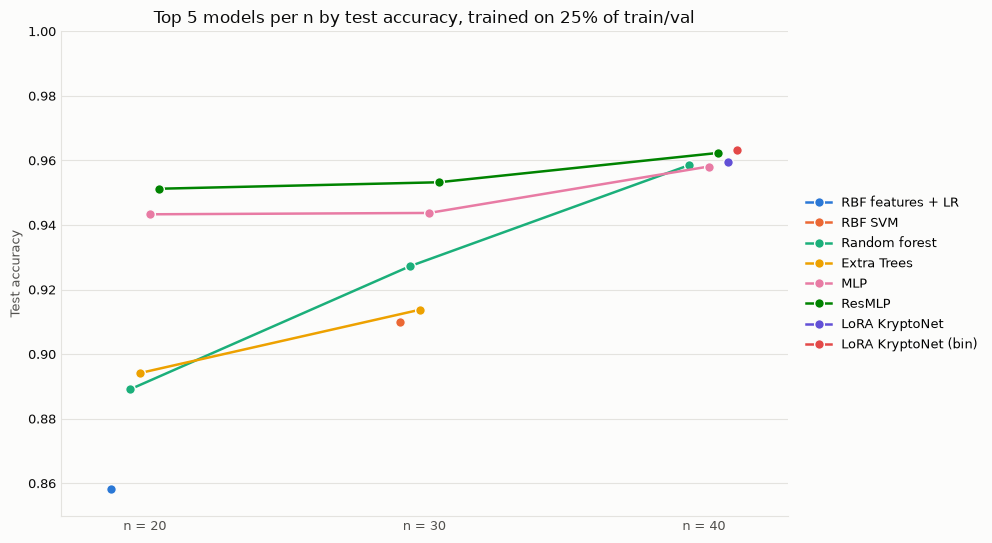

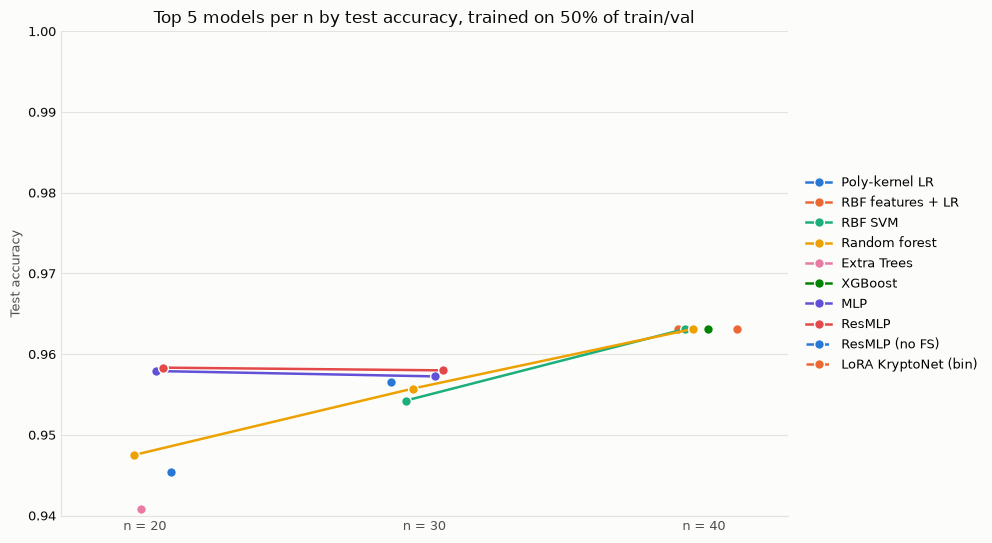

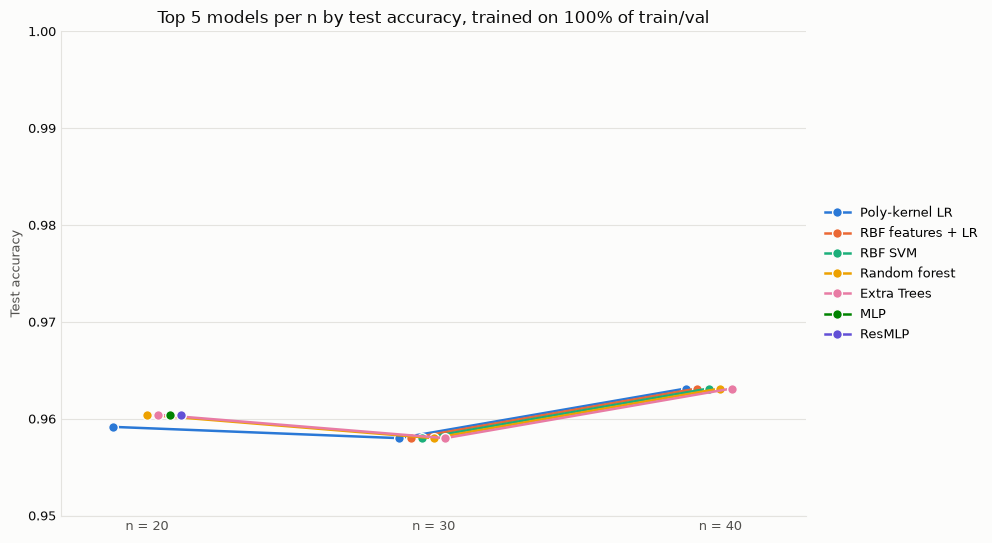

In [7]:
for pct in (25, 50, 100):
    plot_test(pct, top=5)

### Bar charts per data fraction

In [8]:
from matplotlib.patches import Patch


def top_per_n(frac, top):
    """The `top` models per n by test accuracy (ties broken by NAMES order) and the floored lower bound."""
    best = {n: sorted((name for name in NAMES if (name, n, frac) in TEST),
                      key=lambda name: (-TEST[name, n, frac], NAMES.index(name)))[:top] for n in NS}
    lowest = min(TEST[name, n, frac] for n in NS for name in best[n])
    return best, np.floor((lowest - 1e-9) * 100) / 100


def series_styles(names):
    """Colour (and hatch past the 8th model) for each model, in NAMES order."""
    k = len(SERIES_COLORS)
    return {name: (SERIES_COLORS[i % k], "//" if i >= k else None) for i, name in enumerate(names)}


def draw_bars(ax, n, frac, names, styles, lower, title):
    """Bars of test accuracy for `names` at (n, frac), best first, with value labels."""
    names = sorted(names, key=lambda name: -TEST[name, n, frac])
    for x, name in enumerate(names):
        color, hatch = styles[name]
        acc = TEST[name, n, frac]
        ax.bar(x, acc, width=0.72, color=color, hatch=hatch, edgecolor=SURFACE, lw=1.5, zorder=3)
        ax.annotate(f"{acc:.4f}", (x, acc), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7.5, color=INK)
    ax.set_xticks(range(len(names)), names, rotation=35, ha="right", fontsize=8)
    ax.set_ylim(lower, 1.0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(title, fontsize=11)


def add_legend(fig, styles):
    handles = [Patch(facecolor=c, hatch=h, edgecolor=SURFACE, label=name) for name, (c, h) in styles.items()]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=min(len(handles), 5),
               frameon=False, fontsize=9)


def plot_test_bars(pct, top):
    """One panel per n: bars of the `top` models by test accuracy, trained on `pct`% of train/val."""
    frac = pct / 100
    best, lower = top_per_n(frac, top)
    styles = series_styles([name for name in NAMES if any(name in best[n] for n in NS)])
    fig, axes = plt.subplots(1, len(NS), figsize=(15, 5), sharey=True)
    for ax, n in zip(axes, NS):
        draw_bars(ax, n, frac, best[n], styles, lower, f"n = {n}")
    axes[0].set_ylabel("Test accuracy")
    fig.suptitle(f"Top {top} models per n by test accuracy, trained on {pct}% of train/val", fontsize=13, color=INK)
    fig.tight_layout()
    add_legend(fig, styles)
    plt.show()

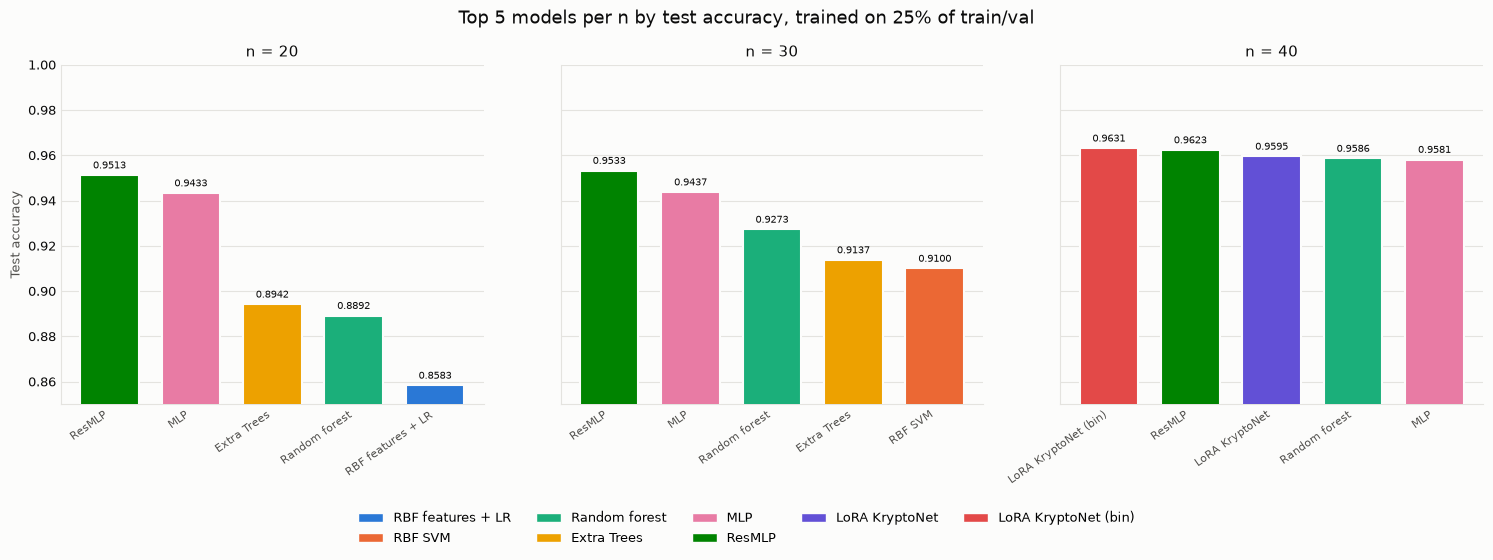

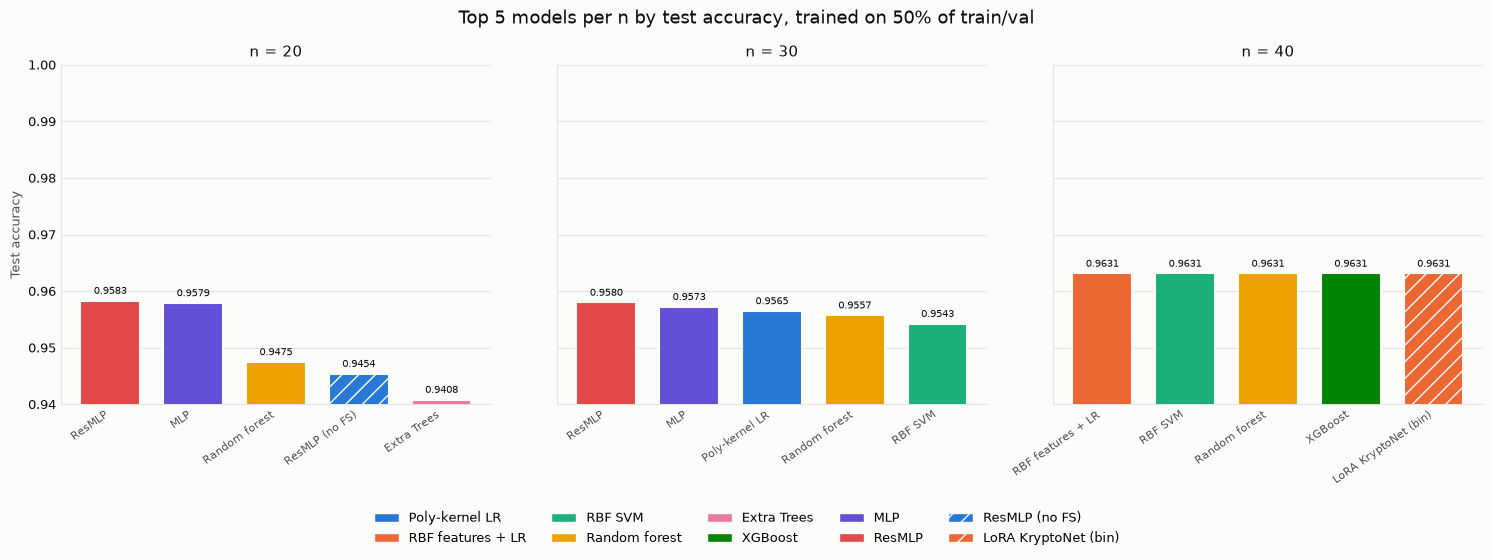

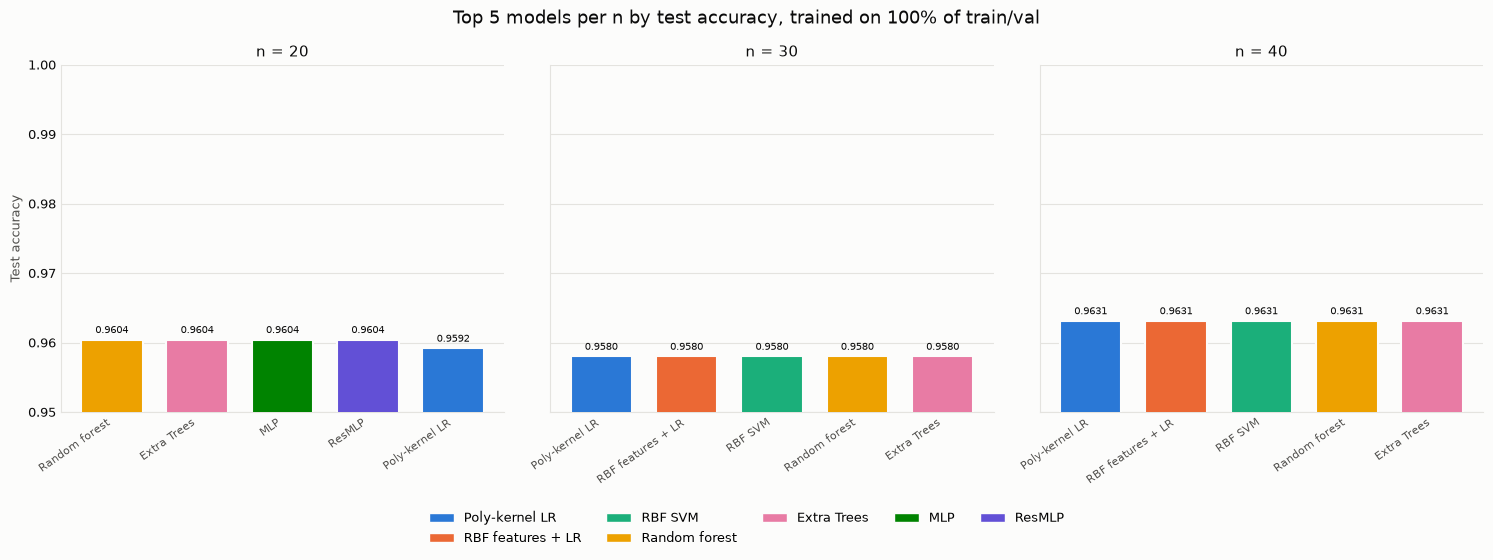

In [9]:
for pct in (25, 50, 100):
    plot_test_bars(pct, top=5)

### All data fractions and all n in one figure

`plot_test_grid(top)` draws the same bars for all nine (data fraction, n) combinations: one row per data fraction
and one column per n. The `top` rule and the lower bound are applied per row (per data fraction), so each row has its
own y range. Colours are fixed for the whole figure, so a model has the same colour in every panel.

In [10]:
def plot_test_grid(top):
    """3 x 3 panels (data fraction x n): bars of the `top` models by test accuracy in each panel."""
    tops = {frac: top_per_n(frac, top) for frac in FRACS}
    styles = series_styles([name for name in NAMES
                            if any(name in tops[frac][0][n] for frac in FRACS for n in NS)])
    fig, axes = plt.subplots(len(FRACS), len(NS), figsize=(15, 14), sharey="row")
    for row, frac in zip(axes, FRACS):
        best, lower = tops[frac]
        for ax, n in zip(row, NS):
            draw_bars(ax, n, frac, best[n], styles, lower, f"n = {n}, {frac:.0%} of train/val")
        row[0].set_ylabel(f"Test accuracy ({frac:.0%} data)")
    fig.suptitle(f"Top {top} models per panel by test accuracy", fontsize=13, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.98))  # leave room for the suptitle
    add_legend(fig, styles)
    plt.show()

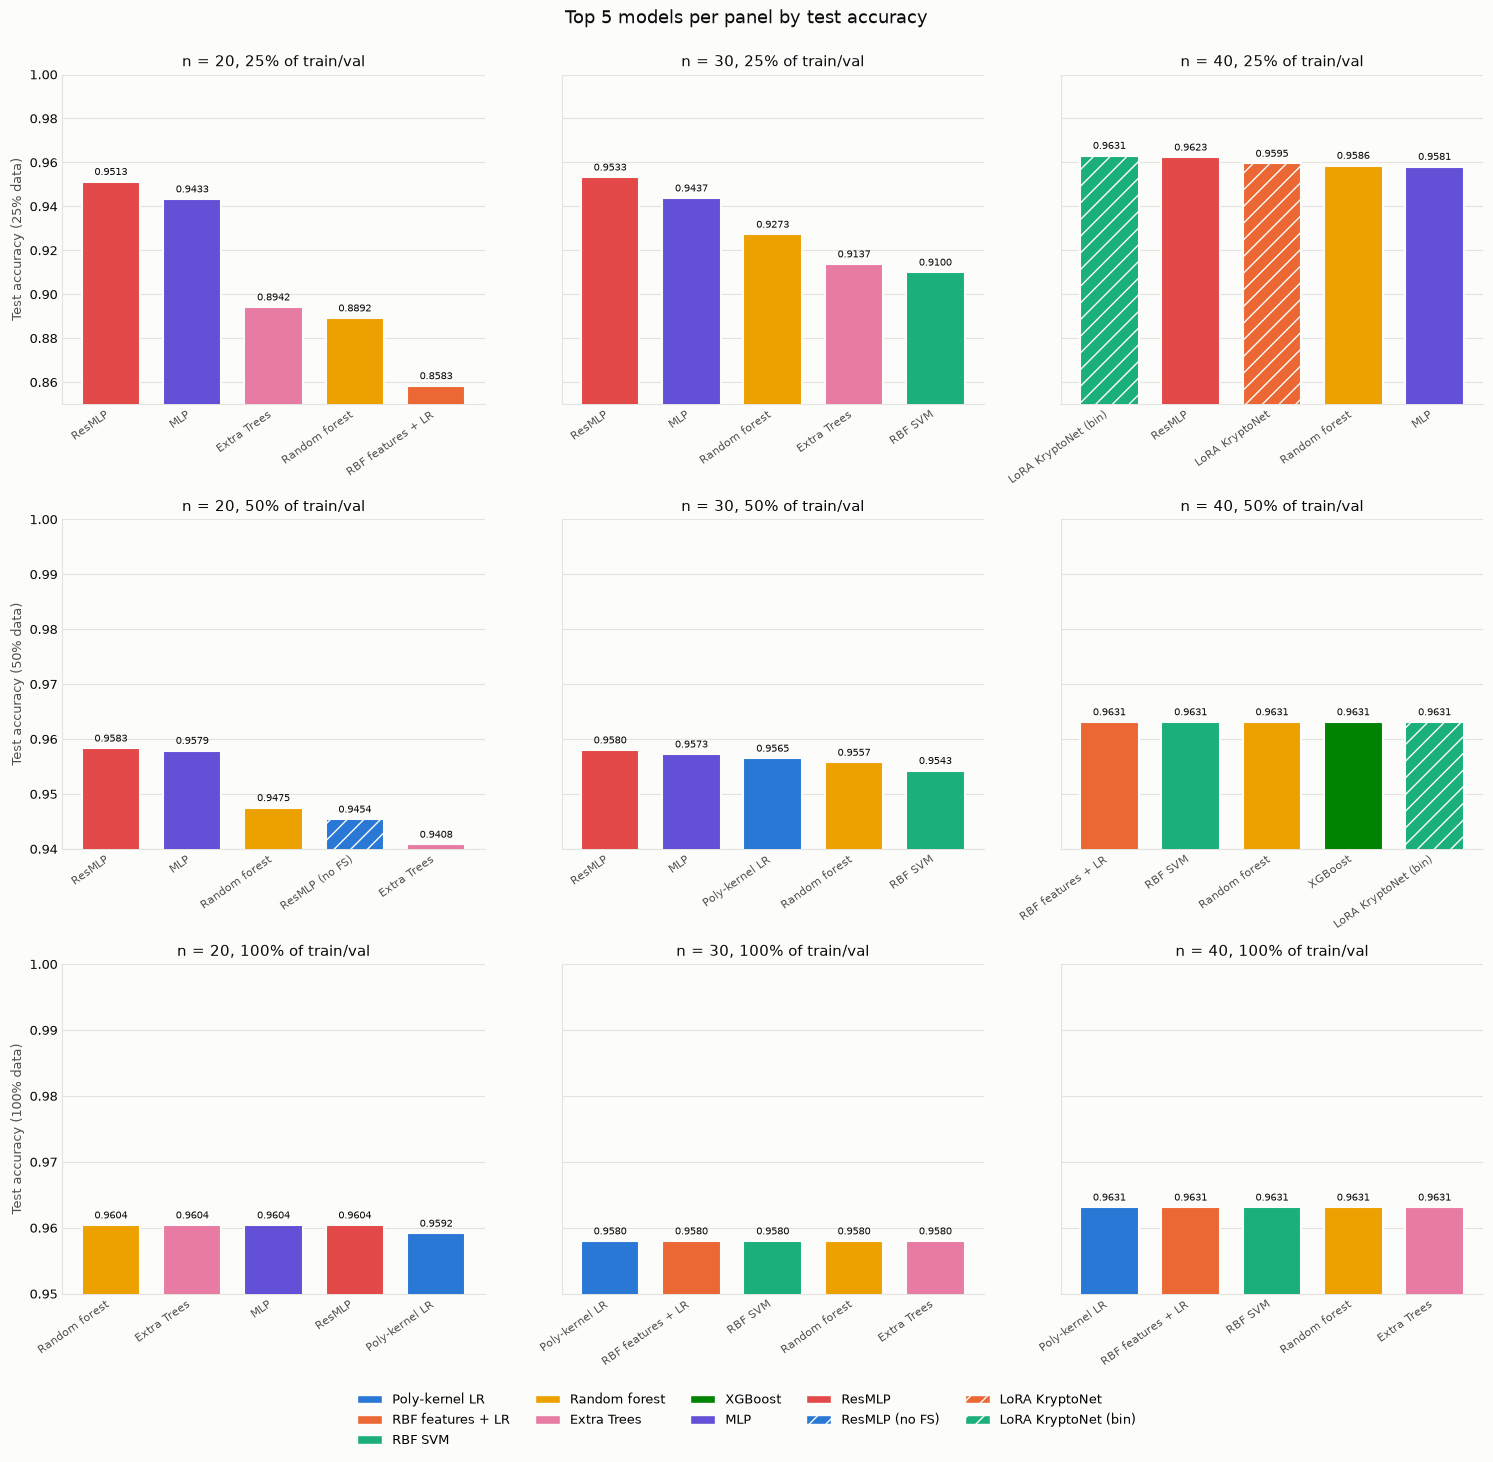

In [11]:
plot_test_grid(top=5)

### Test accuracy table

In [12]:
cols = [(n, frac) for n in NS for frac in FRACS]
W = max(map(len, NAMES))
print(f"{'model':<{W}} " + " ".join(f"{f'n{n} {frac:.0%}':>9}" for n, frac in cols))
for name in NAMES:
    cells = [f"{TEST[name, n, frac]:>9.4f}" if (name, n, frac) in TEST else f"{'-':>9}" for n, frac in cols]
    print(f"{name:<{W}} " + " ".join(cells))

model                            n20 25%   n20 50%  n20 100%   n30 25%   n30 50%  n30 100%   n40 25%   n40 50%  n40 100%
Logistic regression               0.5025    0.5062    0.5238    0.4903    0.5028    0.5240    0.5009    0.4998    0.5184
Linear SVM                        0.5142    0.5038    0.5058    0.4873    0.5085    0.5242    0.5009    0.5041    0.5170
Logistic regression (no FS)       0.5088    0.5167    0.5025    0.5025    0.5105    0.5052    0.4952    0.4947    0.5042
Linear SVM (no FS)                0.5092    0.5125    0.5033    0.5028    0.5062    0.5052    0.5012    0.4983    0.5048
Poly-kernel LR                    0.8550    0.9404    0.9592    0.9080    0.9565    0.9580    0.9569    0.9623    0.9631
Poly-kernel LR (no bin)           0.8079    0.8679    0.9221    0.8518    0.8918    0.9353    0.8922    0.9266    0.9495
Poly-kernel LR (no FS)            0.5504    0.5583    0.6008    0.5200    0.5440    0.5593    0.5119    0.5134    0.5252
Poly-kernel LR (no FS, no bin)  

### Binomial standard error of the test accuracy

Each test accuracy $\hat{p}$ is reported with its binomial standard error $\sqrt{\hat{p}(1-\hat{p})/n_{	ext{test}}}$ as an error bar.
The test set is always the full 20% test split, so $n_{	ext{test}}$ depends only on n (2400, 4000 and 6400 for n = 20, 30, 40).

In [13]:
def binomial_se(p, n_test):
    """Binomial standard error sqrt(p (1 - p) / n_test) of an accuracy p measured on n_test points."""
    return np.sqrt(p * (1 - p) / n_test)


N_TEST = {n: len(SPLITS[n]["test"][1]) for n in NS}
SE = {key: binomial_se(p, N_TEST[key[1]]) for key, p in TEST.items()}  # (model name, n, frac) -> standard error

print("n_test: " + ", ".join(f"n={n}: {N_TEST[n]}" for n in NS))
print(f"{'model':<{W}} " + " ".join(f"{f'n{n} {frac:.0%}':>9}" for n, frac in cols))
for name in NAMES:
    cells = [f"{SE[name, n, frac]:>9.4f}" if (name, n, frac) in SE else f"{'-':>9}" for n, frac in cols]
    print(f"{name:<{W}} " + " ".join(cells))

n_test: n=20: 2400, n=30: 4000, n=40: 6400
model                            n20 25%   n20 50%  n20 100%   n30 25%   n30 50%  n30 100%   n40 25%   n40 50%  n40 100%
Logistic regression               0.0102    0.0102    0.0102    0.0079    0.0079    0.0079    0.0062    0.0062    0.0062
Linear SVM                        0.0102    0.0102    0.0102    0.0079    0.0079    0.0079    0.0062    0.0062    0.0062
Logistic regression (no FS)       0.0102    0.0102    0.0102    0.0079    0.0079    0.0079    0.0062    0.0062    0.0062
Linear SVM (no FS)                0.0102    0.0102    0.0102    0.0079    0.0079    0.0079    0.0062    0.0062    0.0062
Poly-kernel LR                    0.0072    0.0048    0.0040    0.0046    0.0032    0.0032    0.0025    0.0024    0.0024
Poly-kernel LR (no bin)           0.0080    0.0069    0.0055    0.0056    0.0049    0.0039    0.0039    0.0033    0.0027
Poly-kernel LR (no FS)            0.0102    0.0101    0.0100    0.0079    0.0079    0.0078    0.0062    0.0062

## Predict the hidden labels

In [14]:
HIDDEN_DIR = "./hiddenlabels"


def save_hidden(predict, dataset, filename):
    """Predict 0/1 labels for a hidden dataset and save them to HIDDEN_DIR."""
    labels = np.asarray(predict(np.load(f"Datasets/{dataset}-X.npy"))).astype(np.int64)
    assert labels.shape == (10_000,) and set(np.unique(labels)) <= {0, 1}
    os.makedirs(HIDDEN_DIR, exist_ok=True)
    path = os.path.join(HIDDEN_DIR, filename)
    np.save(path, labels)
    print(f"  -> {path} | shape {labels.shape} | fraction of 1s {labels.mean():.4f}")


loaders = {name: loader for name, _, loader in MODELS}
for n in NS:
    candidates = [name for name in NAMES if (name, n, 1.0) in VAL]
    best = max(candidates, key=lambda name: (VAL[name, n, 1.0], TEST[name, n, 1.0], -NAMES.index(name)))
    print(f"n={n}: {best} (100% data, val {VAL[best, n, 1.0]:.4f}, test {TEST[best, n, 1.0]:.4f})")
    save_hidden(loaders[best](n, 1.0), f"hidden-kryptonite-{n}", f"y_predicted_{n}.npy")

adapt_net = load_kryptonet(os.path.join(WEIGHT_ROOT, "lora", "adapt", "best.pt"))
print("40-adapt: LoRA KryptoNet (no FS), weights/lora/adapt/best.pt")
save_hidden(lambda X: torch_predict(adapt_net, X), "hidden-kryptonite-40-adapt", "y_predicted_40_adapt.npy")

n=20: MLP (100% data, val 0.9575, test 0.9604)
  -> ./hiddenlabels\y_predicted_20.npy | shape (10000,) | fraction of 1s 0.4993
n=30: Poly-kernel LR (100% data, val 0.9565, test 0.9580)


  -> ./hiddenlabels\y_predicted_30.npy | shape (10000,) | fraction of 1s 0.5014
n=40: LoRA KryptoNet (100% data, val 0.9570, test 0.9619)
  -> ./hiddenlabels\y_predicted_40.npy | shape (10000,) | fraction of 1s 0.5042
40-adapt: LoRA KryptoNet (no FS), weights/lora/adapt/best.pt
  -> ./hiddenlabels\y_predicted_40_adapt.npy | shape (10000,) | fraction of 1s 0.5142
